In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

 1. Загрузим наш датасет



In [76]:
url = 'https://raw.githubusercontent.com/Earendil961/project/refs/heads/main/ObesityDataSet_raw_and_data_sinthetic.csv'
df = pd.read_csv(url)

In [77]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   object 
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   object 
 12  FAF                             21

**2. EDA**

In [78]:
df.head()


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [79]:
df.isnull().sum()

,0
Age,0
Gender,0
Height,0
Weight,0
CALC,0
FAVC,0
FCVC,0
NCP,0
SCC,0
SMOKE,0


Проверили, что у нас нет пустых значений. А теперь посмотрим как распределены признаки:

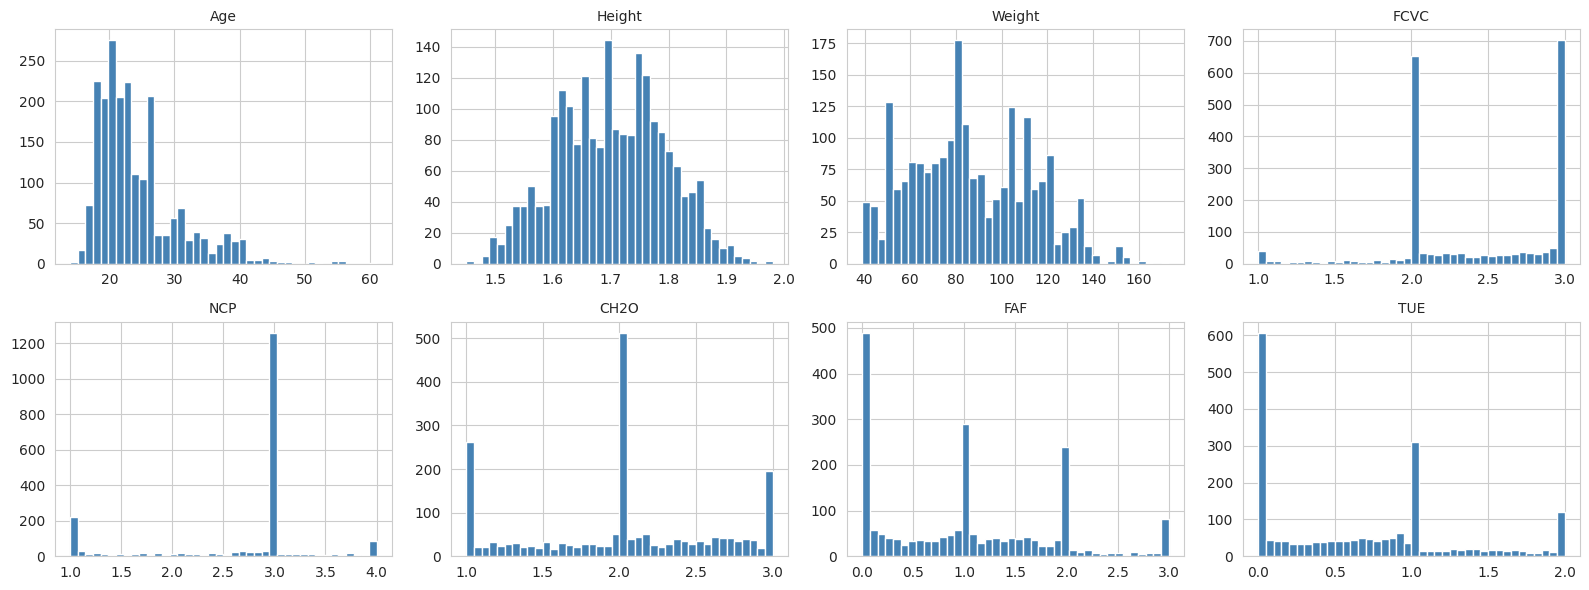

In [80]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

n_cols = len(numeric_cols)
n_rows = (n_cols + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    df[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Заметим, что выбросов у нас нет. Часть величин, таких как Age, Heiht распределены по нормаль ному закону. А другие же величины сосредоточены вокруг конкретных значений на небольших промежутках.

**Корреляционная матрица**

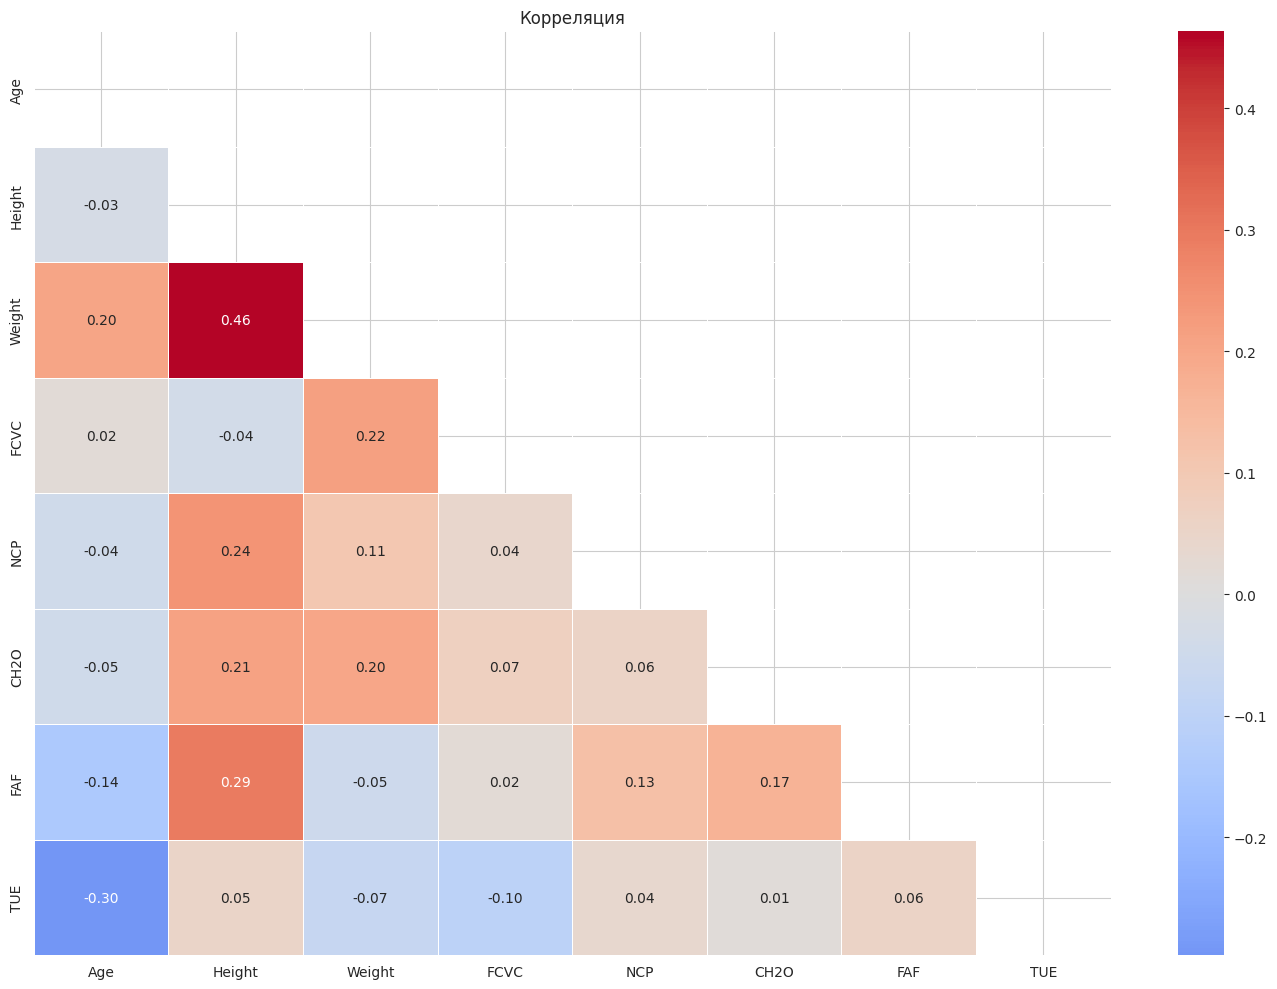

In [81]:
plt.figure(figsize=(14, 10))
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляция')
plt.tight_layout()
plt.show()

**Распределение классов**

Классы примерно распределены одинаково, а значит надо делать многоклассовую классификацию

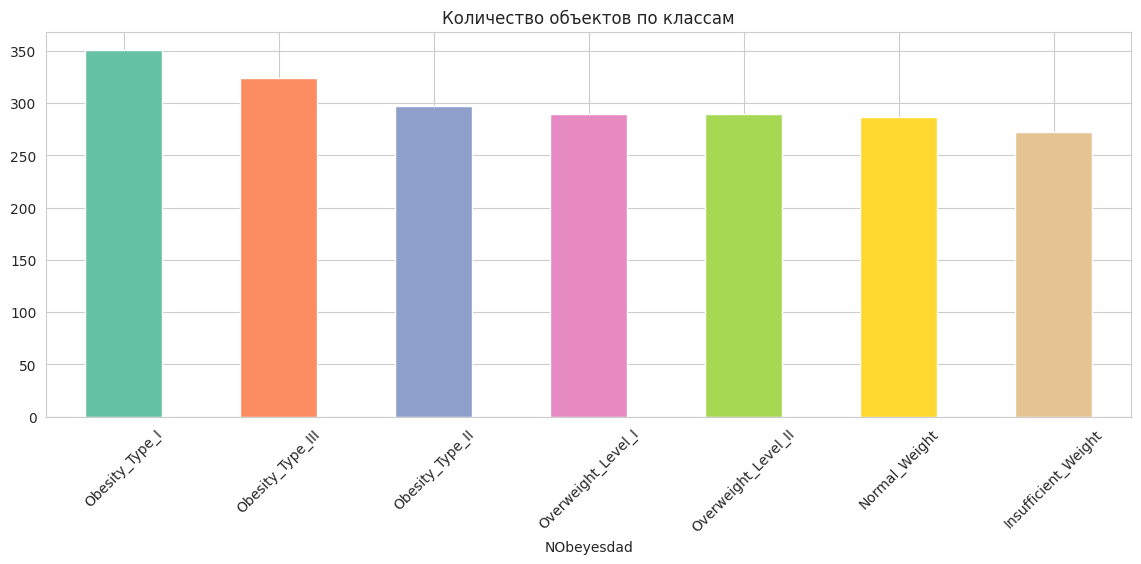

In [82]:
Y = 'NObeyesdad'
fig, axes = plt.subplots(figsize=(14, 5))

df[Y].value_counts().plot.bar(ax=axes, color=sns.color_palette('Set2'))
axes.set_title('Количество объектов по классам')
axes.tick_params(axis='x', rotation=45)

Pairplot

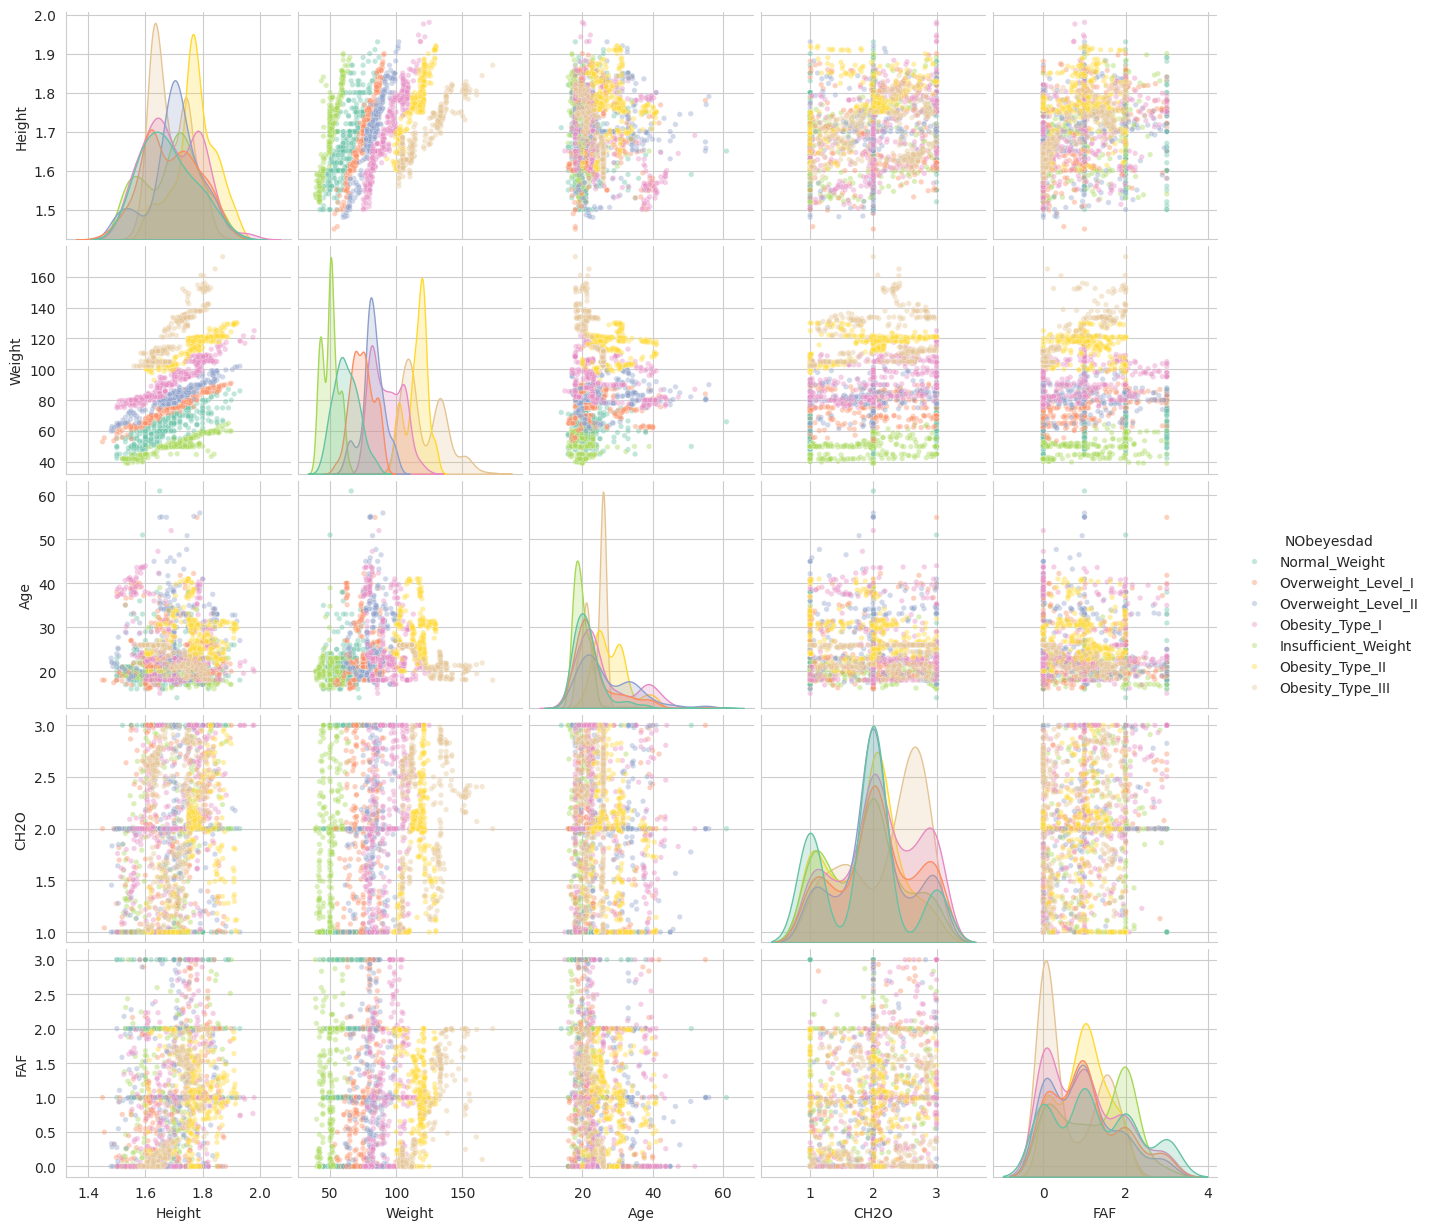

In [83]:
sns.pairplot(df[['Height', 'Weight', 'Age', 'CH2O','FAF' , Y]],
             hue=Y, palette='Set2', plot_kws={'alpha': 0.4, 's': 15})
plt.show()

**3. Подготовка данных**

У нас нет технических переменных, все вожны для иследования. Поэтому мы не будем ничего удалять, а только закодируем часть признаков

Кодирование данных:

In [84]:
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['FAVC'] = df['FAVC'].map({'yes': 1, 'no': 0})
df['SCC'] = df['SCC'].map({'yes': 1, 'no': 0})
df['SMOKE'] = df['SMOKE'].map({'yes': 1, 'no': 0})
df['family_history_with_overweight'] = df['family_history_with_overweight'].map({'yes': 1, 'no': 0})
df['CAEC'] = df['CAEC'].map({'Frequently': 1, 'Sometimes': 2, 'Always': 3, 'no': 0})
df['CALC'] = df['CALC'].map({'Frequently': 1, 'Sometimes': 2, 'Always': 3, 'no': 0})
df = pd.get_dummies(df, columns=['MTRANS'], drop_first=False, dtype=int)

df.head()

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,...,family_history_with_overweight,FAF,TUE,CAEC,NObeyesdad,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21.0,0,1.62,64.0,0,0,2.0,3.0,0,0,...,1,0.0,1.0,2,Normal_Weight,0,0,0,1,0
1,21.0,0,1.52,56.0,2,0,3.0,3.0,1,1,...,1,3.0,0.0,2,Normal_Weight,0,0,0,1,0
2,23.0,1,1.80,77.0,1,0,2.0,3.0,0,0,...,1,2.0,1.0,2,Normal_Weight,0,0,0,1,0
3,27.0,1,1.80,87.0,1,0,3.0,3.0,0,0,...,0,2.0,0.0,2,Overweight_Level_I,0,0,0,0,1
4,22.0,1,1.78,89.8,2,0,2.0,1.0,0,0,...,0,0.0,0.0,2,Overweight_Level_II,0,0,0,1,0


Сделали для всех методов. Теперь будем отдельно делать регрессию и дерево:

In [87]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

feature_cols = ['Weight', 'Height', 'Age', 'FCVC', 'NCP', 'TUE', 'FAF', 'CH2O', 'SMOKE', 'Gender', 'SCC', 'family_history_with_overweight', 'CAEC', 'CALC', 'MTRANS_Automobile',	'MTRANS_Bike',	'MTRANS_Motorbike',	'MTRANS_Public_Transportation',	'MTRANS_Walking']
X_all = df[feature_cols].copy()

X_reg = X_all.drop(columns=['Weight'])
y_reg = X_all['Weight'].values

X_train_reg, X_test_reg, y_train_reg, y_test_reg =  train_test_split(X_reg, y_reg, test_size=0.2, random_state=123)

scaler_reg = StandardScaler()
X_train_reg_sc = scaler_reg.fit_transform(X_train_reg)
X_test_reg_sc = scaler_reg.transform(X_test_reg)


In [88]:
X_cls = X_all
y_cls = LabelEncoder().fit_transform( df[Y])

X_train, X_test, y_train_cls, y_test_cls =  train_test_split(X_cls, y_cls, test_size=0.2, random_state=123, stratify=y_cls)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Pipeline:

In [89]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

scores = cross_val_score(pipe, X_train, y_train_cls, cv=cv, scoring='f1_macro')

print(scores.mean())

0.8596126111478555


**4. Регрессия**

Предсазываем параметр 'Weight' - сколько весит человек

Начнем метода наименьших квадратов

In [90]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lr = LinearRegression().fit(X_train_reg_sc, y_train_reg)
y_pred_lr = lr.predict(X_test_reg_sc)

pd.DataFrame({
    'MSE': [mean_squared_error(y_test_reg, y_pred_lr)],
    'RMSE': [np.sqrt(mean_squared_error(y_test_reg, y_pred_lr))],
    'MAE': [mean_absolute_error(y_test_reg, y_pred_lr)],
    'R²': [r2_score(y_test_reg, y_pred_lr)],
}, index=['OLS'])

,MSE,RMSE,MAE,R²
OLS,337.70896,18.376859,15.000866,0.502616


Lasso:

In [91]:
models_reg = {
    'OLS': LinearRegression(),
    'Ridge (a = 1)': Ridge(alpha=1),
    'Ridge (a = 5)': Ridge(alpha=5),
    'Ridge (a = 10)': Ridge(alpha=10),
    'Ridge (a = 50)': Ridge(alpha=50),
    'Ridge (a = 100)': Ridge(alpha=100),
    'Lasso (a = 0.05)': Lasso(alpha=0.05),
    'Lasso (a = 1)': Lasso(alpha=1),
    'Lasso (a = 5)': Lasso(alpha=5),
    'Lasso (a = 10)': Lasso(alpha=10),
    'Lasso (a = 50)': Lasso(alpha=50),
    'Lasso (a = 100)': Lasso(alpha=100),
    'ElasticNet': ElasticNet(alpha=1, l1_ratio=0.05)

}

results_reg = []
for name, model in models_reg.items():
    model.fit(X_train_reg_sc, y_train_reg)
    y_pred = model.predict(X_test_reg_sc)
    results_reg.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_test_reg, y_pred)),
        'MAE': mean_absolute_error(y_test_reg, y_pred),
        'R²': r2_score(y_test_reg, y_pred),
    })

pd.DataFrame(results_reg).set_index('Model').round(2)

,RMSE,MAE,R²
Model,,,
OLS,18.38,15.00,0.50
Ridge (a = 1),18.38,15.00,0.50
Ridge (a = 5),18.38,15.00,0.50
Ridge (a = 10),18.37,15.01,0.50
Ridge (a = 50),18.37,15.03,0.50
Ridge (a = 100),18.39,15.07,0.50
Lasso (a = 0.05),18.38,15.02,0.50
Lasso (a = 1),18.77,15.65,0.48
Lasso (a = 5),21.93,18.36,0.29


Лучший результат по метрике R^2 - 0.5, что достаточно плохой результат. Поэтому предлагаю попробовать деревья

**Классификация**

In [92]:
from sklearn.multiclass import OneVsRestClassifier

le = LabelEncoder().fit(df[Y])
class_names = le.classes_

log_reg_ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=42)).fit(X_train_sc, y_train_cls)
log_reg_mn = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_sc, y_train_cls)

y_pred_ovr = log_reg_ovr.predict(X_test_sc)
y_pred_mn = log_reg_mn.predict(X_test_sc)

pd.DataFrame({
    'OvR Accuracy': [accuracy_score(y_test_cls, y_pred_ovr)],
    'OvR F1 (macro)': [f1_score(y_test_cls, y_pred_ovr, average='macro')],
    'Softmax Accuracy': [accuracy_score(y_test_cls, y_pred_mn)],
    'Softmax F1 (macro)': [f1_score(y_test_cls, y_pred_mn, average='macro')],
}, index=['LogReg']).round(4)

,OvR Accuracy,OvR F1 (macro),Softmax Accuracy,Softmax F1 (macro)
LogReg,0.7565,0.7442,0.8723,0.869


Результат по метрикам вышел хороший. Посмотрим на него с помощью матриц

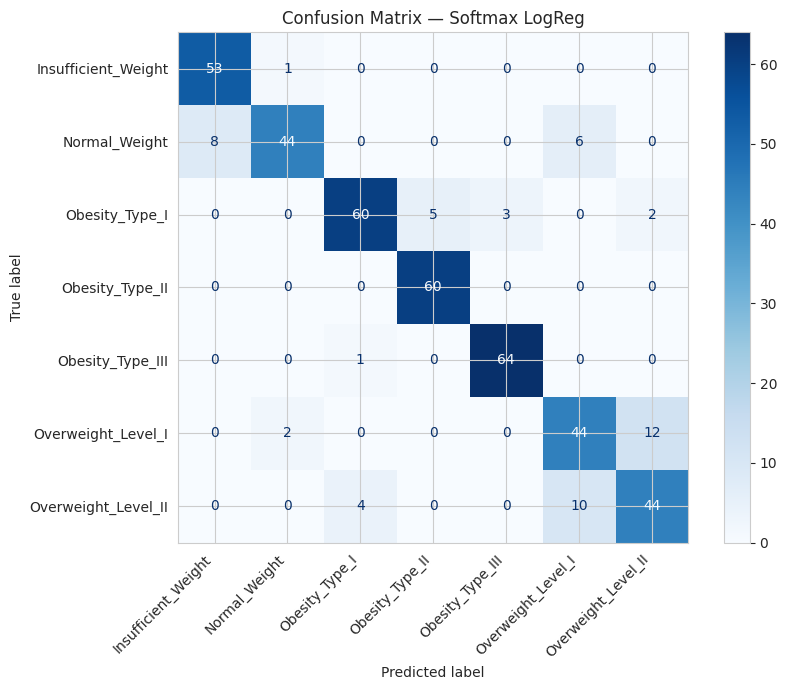

In [93]:
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(y_test_cls, y_pred_mn, display_labels=class_names, ax=ax, cmap='Blues')
ax.set_title('Confusion Matrix — Softmax LogReg')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [94]:
report = classification_report(y_test_cls, y_pred_mn, target_names=class_names, output_dict=True)
pd.DataFrame(report).T.round(3)

,precision,recall,f1-score,support
Insufficient_Weight,0.869,0.981,0.922,54.000
Normal_Weight,0.936,0.759,0.838,58.000
Obesity_Type_I,0.923,0.857,0.889,70.000
Obesity_Type_II,0.923,1.000,0.960,60.000
Obesity_Type_III,0.955,0.985,0.970,65.000
Overweight_Level_I,0.733,0.759,0.746,58.000
Overweight_Level_II,0.759,0.759,0.759,58.000
accuracy,0.872,0.872,0.872,0.872
macro avg,0.871,0.871,0.869,423.000
weighted avg,0.874,0.872,0.871,423.000


**5. Деревья решений**

Классификация: попробуем сразу несколько методов и выпишем каждый метод отдельно с его результатами



In [95]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

dt_cls = DecisionTreeClassifier(max_depth=10, random_state=42, criterion='gini')
dt_cls.fit(X_train, y_train_cls)
y_pred_dt = dt_cls.predict(X_test)

pd.DataFrame({
    'Accuracy': [accuracy_score(y_test_cls, y_pred_dt)],
    'F1 (macro)': [f1_score(y_test_cls, y_pred_dt, average='macro')],
}, index=['DecisionTree (depth=10)']).round(4)

,Accuracy,F1 (macro)
DecisionTree (depth=10),0.9078,0.9052


In [96]:
dt_cls2 = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)
dt_cls2.fit(X_train, y_train_cls)
y_pred_dt2 = dt_cls2.predict(X_test)

pd.DataFrame({
    'Accuracy': [accuracy_score(y_test_cls, y_pred_dt2)],
    'F1 (macro)': [f1_score(y_test_cls, y_pred_dt2, average='macro')],
}, index=['RandomForestClassifier (т=500)']).round(4)


,Accuracy,F1 (macro)
RandomForestClassifier (т=500),0.9622,0.9616


In [97]:
dt_cls3 =  HistGradientBoostingClassifier(random_state=42)
dt_cls3.fit(X_train, y_train_cls)
y_pred_dt3 = dt_cls3.predict(X_test)

pd.DataFrame({
    'Accuracy': [accuracy_score(y_test_cls, y_pred_dt3)],
    'F1 (macro)': [f1_score(y_test_cls, y_pred_dt3, average='macro')],
}, index=['HistGradientBoostingClassifier']).round(4)

,Accuracy,F1 (macro)
HistGradientBoostingClassifier,0.9835,0.9834


Деревья выдают достаточно хорошие показатели. Но лучший результат оказался у HistGradientBoostingClassifier( Точность -- 0.98 и F1-мера -- 0.98).

Теперь аналогичным способом рассмотрим регрессию:

In [113]:
dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42, criterion='squared_error')
dt_reg.fit(X_train_reg, y_train_reg)
y_pred_dt_reg = dt_reg.predict(X_test_reg)

pd.DataFrame({
    'RMSE': [np.sqrt(mean_squared_error(y_test_reg, y_pred_dt_reg))],
    'MAE': [mean_absolute_error(y_test_reg, y_pred_dt_reg)],
    'R^2': [r2_score(y_test_reg, y_pred_dt_reg)],
}, index=['DecisionTree Regressor']).round(4)

,RMSE,MAE,R^2
DecisionTree Regressor,14.1794,10.0947,0.7039


In [112]:
from sklearn.ensemble import RandomForestRegressor
dt_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
dt_reg.fit(X_train_reg, y_train_reg)
y_pred_dt_reg = dt_reg.predict(X_test_reg)

pd.DataFrame({
    'RMSE': [np.sqrt(mean_squared_error(y_test_reg, y_pred_dt_reg))],
    'MAE': [mean_absolute_error(y_test_reg, y_pred_dt_reg)],
    'R^2': [r2_score(y_test_reg, y_pred_dt_reg)],
}, index=['RandomForest Regressor']).round(4)

,RMSE,MAE,R^2
RandomForest Regressor,8.0616,4.8585,0.9043


In [100]:
from sklearn.ensemble import HistGradientBoostingRegressor
dt_reg = HistGradientBoostingRegressor(random_state=42)
dt_reg.fit(X_train_reg, y_train_reg)
y_pred_dt_reg = dt_reg.predict(X_test_reg)

pd.DataFrame({
    'RMSE': [np.sqrt(mean_squared_error(y_test_reg, y_pred_dt_reg))],
    'MAE': [mean_absolute_error(y_test_reg, y_pred_dt_reg)],
    'R^2': [r2_score(y_test_reg, y_pred_dt_reg)],
}, index=['HistGradientBoosting Regressor']).round(4)

,RMSE,MAE,R^2
HistGradientBoosting Regressor,8.7228,5.5528,0.8879


По всем показателям(RMSE, R^2) деревья намного лучше обычной регрессии. Самым лучшим оказался случайный лес.

**6. Кросс валидация**




In [101]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_cv = {
    'LogReg': LogisticRegression(max_iter=1000, random_state=42),
    'DecisionTree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'HistGradientBoostingClassifier': HistGradientBoostingClassifier(random_state=42),
    'RandomForestClassifier': RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1),
}

cv_results = []
for name, model in models_cv.items():
    scores = cross_val_score(model, X_train_sc, y_train_cls, cv=cv, scoring='f1_macro')
    cv_results.append({'Model': name, 'CV F1 mean': scores.mean(), 'CV F1 std': scores.std()})

pd.DataFrame(cv_results).set_index('Model').round(4)

,CV F1 mean,CV F1 std
Model,,
LogReg,0.8545,0.0204
DecisionTree,0.9141,0.0102
HistGradientBoostingClassifier,0.9694,0.0129
RandomForestClassifier,0.9480,0.0178


**7. Подбор гиперпараметров деревьев**



In [102]:
param_grid = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy'],
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid, cv=cv, scoring='f1_macro', n_jobs=-1
)
grid_search.fit(X_train_sc, y_train_cls)

grid_search.best_params_, grid_search.best_score_.round(4)

({'criterion': 'entropy',
  'max_depth': 15,
  'min_samples_leaf': 2,
  'min_samples_split': 2},
 np.float64(0.9466))

**8. Отбор признаков**

Проверим признаки на важность

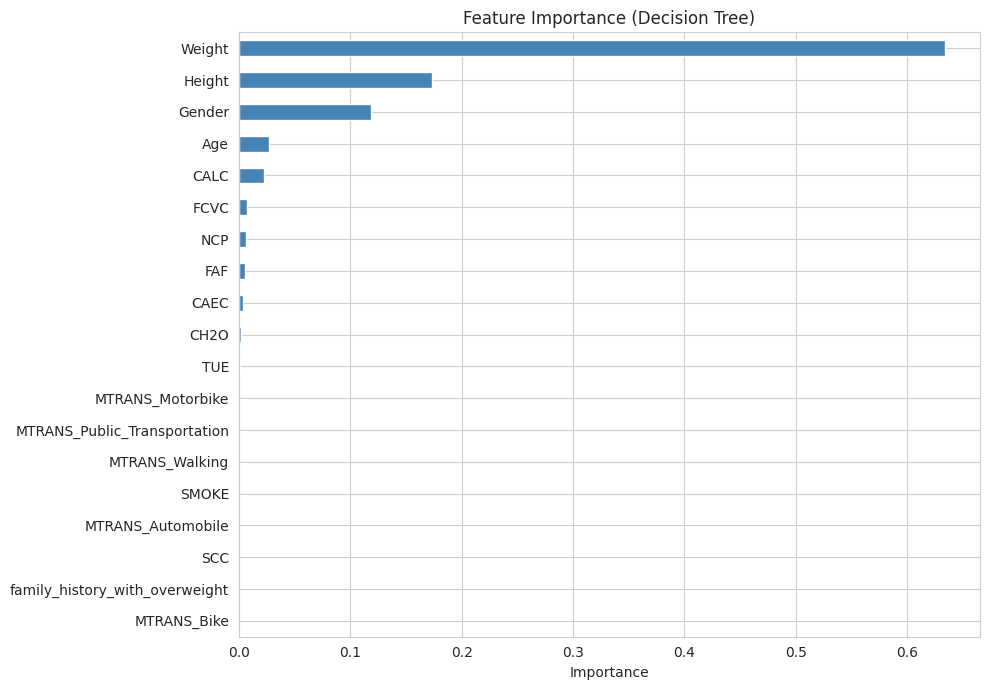

In [106]:
best_dt = grid_search.best_estimator_
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
importances = pd.Series(best_dt.feature_importances_, index=X_all.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
importances.plot.barh(ax=ax, color='steelblue')
ax.set_title('Feature Importance (Decision Tree)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

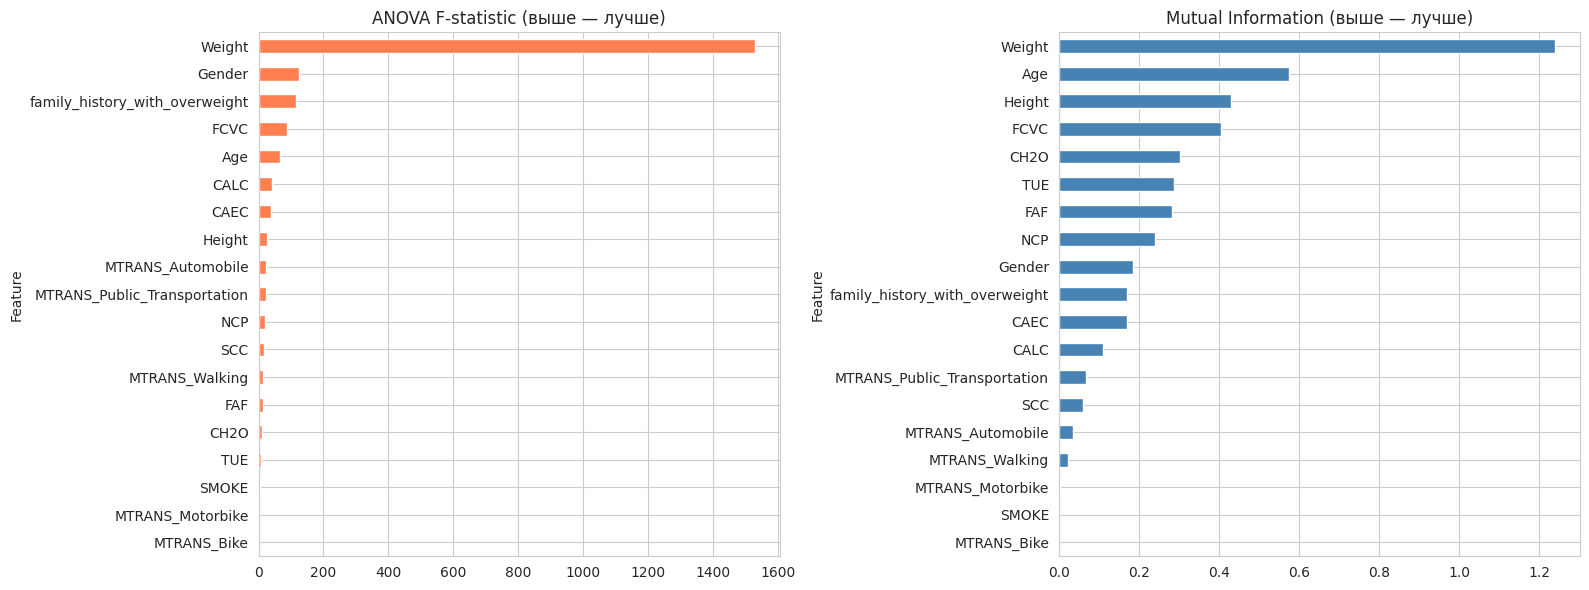

In [110]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

f_selector = SelectKBest(f_classif, k='all').fit(X_train_sc, y_train_cls)
mi_selector = SelectKBest(mutual_info_classif, k='all').fit(X_train_sc, y_train_cls)

scores_df = pd.DataFrame({
    'Feature': X_cls.columns,
    'F-statistic': f_selector.scores_,
    'Mutual Information': mi_selector.scores_
}).sort_values('F-statistic', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

scores_df.sort_values('F-statistic').plot.barh(x='Feature', y='F-statistic', ax=axes[0],
                                                 color='coral', legend=False)
axes[0].set_title('ANOVA F-statistic (выше — лучше)')

scores_df.sort_values('Mutual Information').plot.barh(x='Feature', y='Mutual Information', ax=axes[1],
                                                        color='steelblue', legend=False)
axes[1].set_title('Mutual Information (выше — лучше)')

plt.tight_layout()
plt.show()

Проверим первую гипотезу

In [115]:
from sklearn.feature_selection import RFE

estimator = LogisticRegression(max_iter=1000, random_state=42)
rfe = RFE(estimator, n_features_to_select=7, step=1)
rfe.fit(X_train_sc, y_train_cls)

rfe_df = pd.DataFrame({
    'Feature': X_cls.columns,
    'Ranking': rfe.ranking_,
    'Selected': rfe.support_
}).sort_values('Ranking')

rfe_df

,Feature,Ranking,Selected
0,Weight,1,True
1,Height,1,True
2,Age,1,True
3,FCVC,1,True
13,CALC,1,True
9,Gender,1,True
17,MTRANS_Public_Transportation,1,True
11,family_history_with_overweight,2,False
4,NCP,3,False
12,CAEC,4,False


In [116]:
X_train_rfe = rfe.transform(X_train_sc)
X_test_rfe = rfe.transform(X_test_sc)

model_rfe = LogisticRegression(max_iter=1000, random_state=42)
model_rfe.fit(X_train_rfe, y_train_cls)
y_pred_rfe = model_rfe.predict(X_test_rfe)

pd.DataFrame({
    'Method': ['All features', 'RFE (7 features)'],
    'n_features': [X_train_sc.shape[1], X_train_rfe.shape[1]],
    'Accuracy': [
        accuracy_score(y_test_cls, log_reg_mn.predict(X_test_sc)),
        accuracy_score(y_test_cls, y_pred_rfe)
    ],
    'F1 (macro)': [
        f1_score(y_test_cls, log_reg_mn.predict(X_test_sc), average='macro'),
        f1_score(y_test_cls, y_pred_rfe, average='macro')
    ]
}).round(4)

,Method,n_features,Accuracy,F1 (macro)
0,All features,19,0.8723,0.8690
1,RFE (7 features),7,0.8842,0.8822
